In [1]:
import os
import json
import random
import torch
import torch.nn as nn
from torchvision import transforms
from PIL import Image
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Must match the training architecture exactly
class SimpsonsCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1),
                nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1),
                nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(
            block(3, 32), block(32, 64), block(64, 128),
            block(128, 256), block(256, 256),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )
    def forward(self, x):
        x = self.features(x); x = self.gap(x)
        return self.classifier(x)

Device: cpu


In [2]:
def infer(data_dir, model_path="model.pth", output_path="results.json"):
    ckpt = torch.load(model_path, map_location=device)
    class_to_idx = ckpt["class_to_idx"]
    idx_to_class = {v: k for k, v in class_to_idx.items()}
    img_size = ckpt.get("img_size", 128)

    model = SimpsonsCNN(num_classes=len(class_to_idx)).to(device)
    model.load_state_dict(ckpt["model_state"])
    model.eval()

    tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3),
    ])

    image_files = []
    for root, _, files in os.walk(data_dir):
        for f in files:
            if f.startswith("._"):
                continue
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                image_files.append(os.path.join(root, f))
    print(f"Found {len(image_files)} images in {data_dir}")

    results = {}
    with torch.no_grad():
        for path in image_files:
            try:
                img = Image.open(path).convert("RGB")
                x = tf(img).unsqueeze(0).to(device)
                out = model(x)
                _, pred = out.max(1)
                results[os.path.basename(path)] = idx_to_class[pred.item()]
            except Exception as e:
                print(f"Error on {path}: {e}")
                results[os.path.basename(path)] = list(idx_to_class.values())[0]

    with open(output_path, "w") as f:
        json.dump(results, f, indent=2)
    print(f"✔ Saved {len(results)} predictions to {output_path}")
    return results

In [3]:
def run_test(test_dir, output_name):
    if not os.path.exists(test_dir):
        print(f"❌ {test_dir} not found, skipping.")
        return None
    print(f"\n{'='*60}\nRunning inference on: {test_dir}\n{'='*60}")
    results = infer(test_dir, model_path="model.pth", output_path=output_name)

    print("\nFirst 10 predictions:")
    for fname, cls in list(results.items())[:10]:
        print(f"  {fname}  →  {cls}")

    counts = Counter(results.values())
    print("\nPrediction distribution:")
    for cls, n in counts.most_common():
        print(f"  {cls:30s} {n}")

    # If folder is nested by class, compute accuracy + Macro F1
    subdirs = [d for d in os.listdir(test_dir)
               if os.path.isdir(os.path.join(test_dir, d))]
    if subdirs:
        print("\n📊 Computing accuracy from folder names:")
        y_true, y_pred = [], []
        per_class = {}
        for sub in subdirs:
            sub_path = os.path.join(test_dir, sub)
            for f in os.listdir(sub_path):
                if f.startswith("._") or not f.lower().endswith((".jpg",".jpeg",".png")):
                    continue
                pred = results.get(f)
                if pred is None: continue
                y_true.append(sub); y_pred.append(pred)
                per_class.setdefault(sub, [0,0])
                per_class[sub][0] += int(pred == sub)
                per_class[sub][1] += 1

        if y_true:
            acc = sum(int(t==p) for t,p in zip(y_true, y_pred)) / len(y_true)
            print(f"\nOverall accuracy: {acc:.4f} ({len(y_true)} images)")
            print("\nPer-class accuracy (sorted by image count):")
            for cls, (c, t) in sorted(per_class.items(), key=lambda x: -x[1][1]):
                print(f"  {cls:30s} {c:4d}/{t:4d} = {c/t:.3f}")

            try:
                from sklearn.metrics import f1_score
                f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
                print(f"\n Macro F1: {f1:.4f}")
            except Exception as e:
                print("F1 calc skipped:", e)
    return results

# IMPORTANT: write path to testing data here
run_test("inference_test/inference_test", "results_inference_test.json")
run_test("test_simpsons/test_simpsons",   "results.json")


Running inference on: inference_test/inference_test
Found 4172 images in inference_test/inference_test
✔ Saved 4172 predictions to results_inference_test.json

First 10 predictions:
  pic_00000.jpg  →  abraham_grampa_simpson
  pic_00001.jpg  →  abraham_grampa_simpson
  pic_00002.jpg  →  abraham_grampa_simpson
  pic_00003.jpg  →  abraham_grampa_simpson
  pic_00004.jpg  →  abraham_grampa_simpson
  pic_00005.jpg  →  abraham_grampa_simpson
  pic_00006.jpg  →  abraham_grampa_simpson
  pic_00007.jpg  →  abraham_grampa_simpson
  pic_00008.jpg  →  abraham_grampa_simpson
  pic_00009.jpg  →  abraham_grampa_simpson

Prediction distribution:
  homer_simpson                  458
  moe_szyslak                    313
  ned_flanders                   285
  lisa_simpson                   273
  marge_simpson                  264
  bart_simpson                   263
  krusty_the_clown               241
  charles_montgomery_burns       230
  principal_skinner              218
  milhouse_van_houten       

{'pic_0731.jpg': 'sideshow_bob',
 'pic_0732.jpg': 'sideshow_bob',
 'pic_0733.jpg': 'sideshow_bob',
 'pic_0734.jpg': 'sideshow_bob',
 'pic_0735.jpg': 'sideshow_bob',
 'pic_0736.jpg': 'sideshow_bob',
 'pic_0737.jpg': 'sideshow_bob',
 'pic_0738.jpg': 'sideshow_bob',
 'pic_0739.jpg': 'sideshow_bob',
 'pic_0740.jpg': 'sideshow_bob',
 'pic_0741.jpg': 'sideshow_bob',
 'pic_0742.jpg': 'sideshow_bob',
 'pic_0743.jpg': 'sideshow_bob',
 'pic_0744.jpg': 'sideshow_bob',
 'pic_0745.jpg': 'sideshow_bob',
 'pic_0746.jpg': 'sideshow_bob',
 'pic_0747.jpg': 'sideshow_bob',
 'pic_0748.jpg': 'cletus_spuckler',
 'pic_0749.jpg': 'sideshow_bob',
 'pic_0750.jpg': 'sideshow_bob',
 'pic_0751.jpg': 'sideshow_bob',
 'pic_0752.jpg': 'sideshow_bob',
 'pic_0753.jpg': 'sideshow_bob',
 'pic_0754.jpg': 'sideshow_bob',
 'pic_0755.jpg': 'sideshow_bob',
 'pic_0756.jpg': 'sideshow_bob',
 'pic_0757.jpg': 'sideshow_bob',
 'pic_0758.jpg': 'sideshow_bob',
 'pic_0759.jpg': 'sideshow_bob',
 'pic_0760.jpg': 'sideshow_bob',
 'pic_0

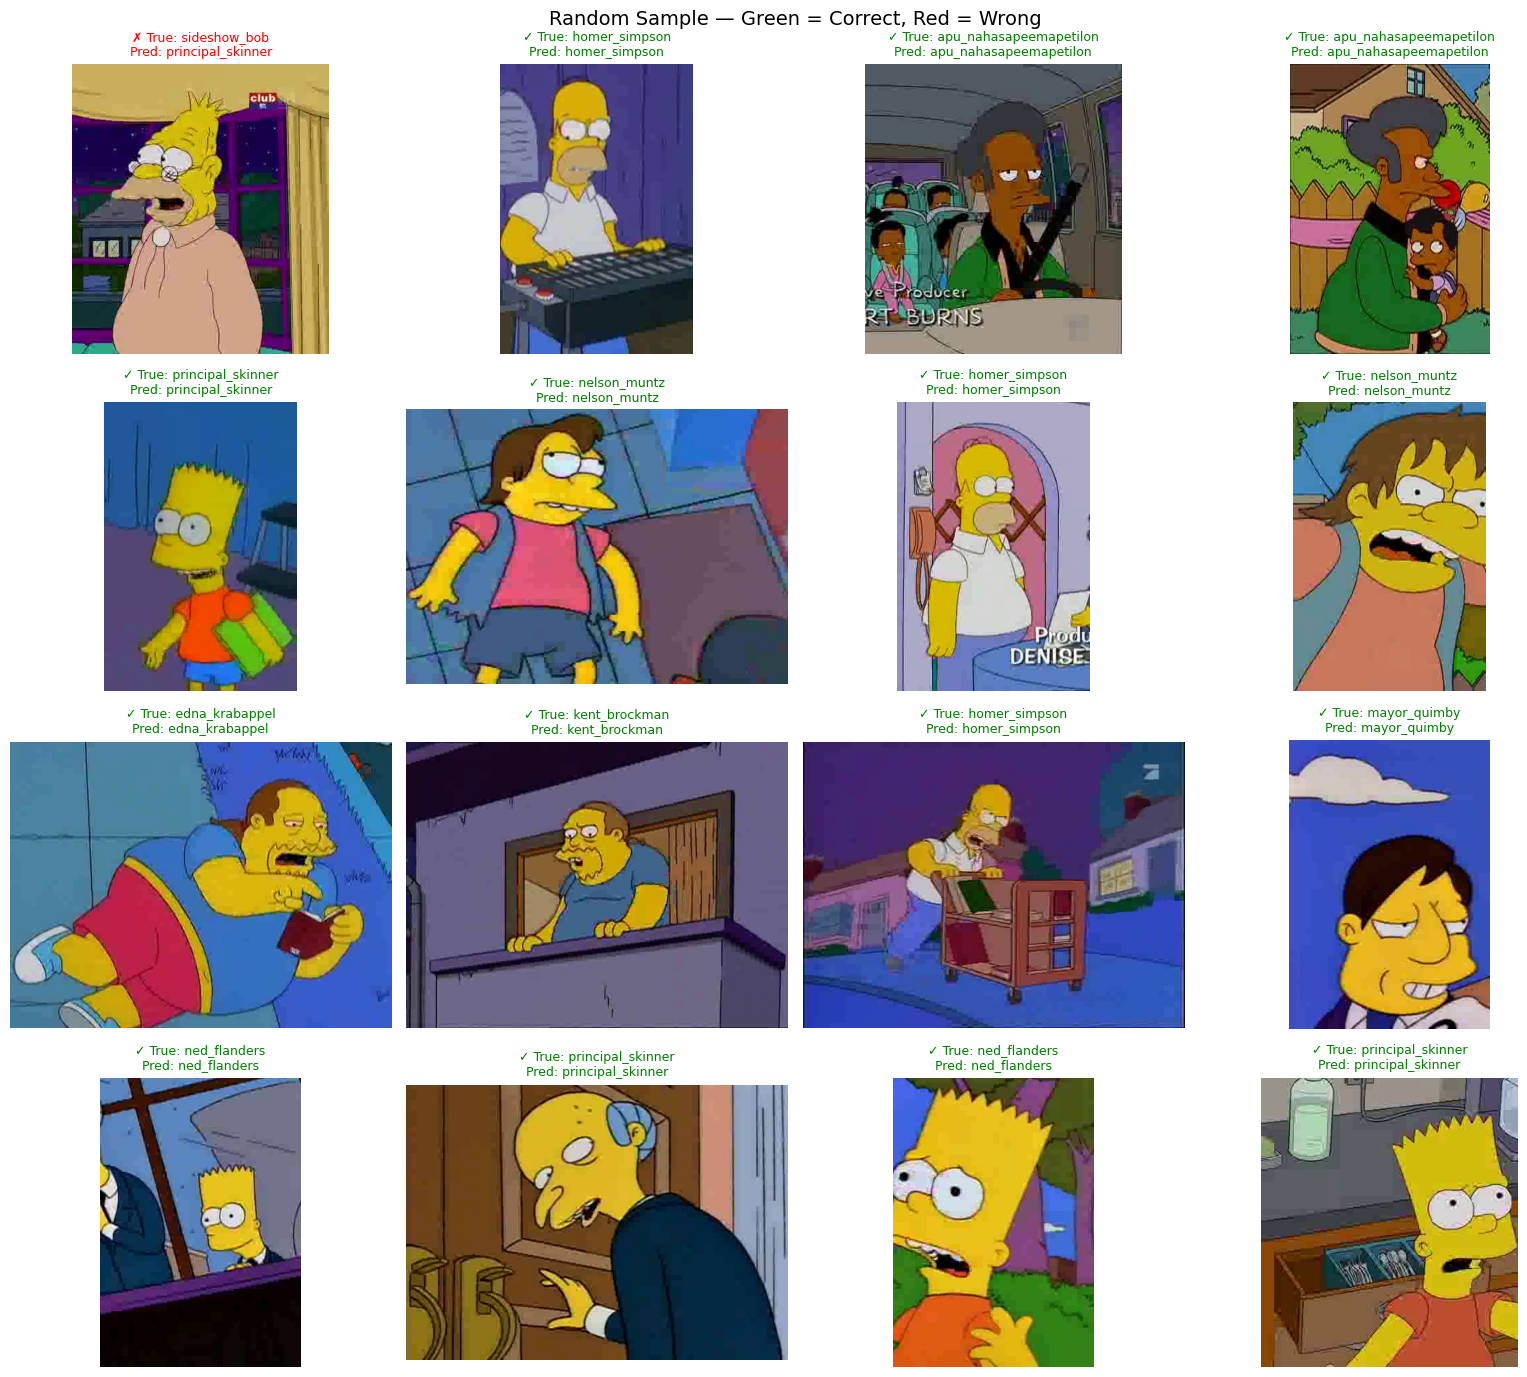


Total wrong predictions: 113 / 1762


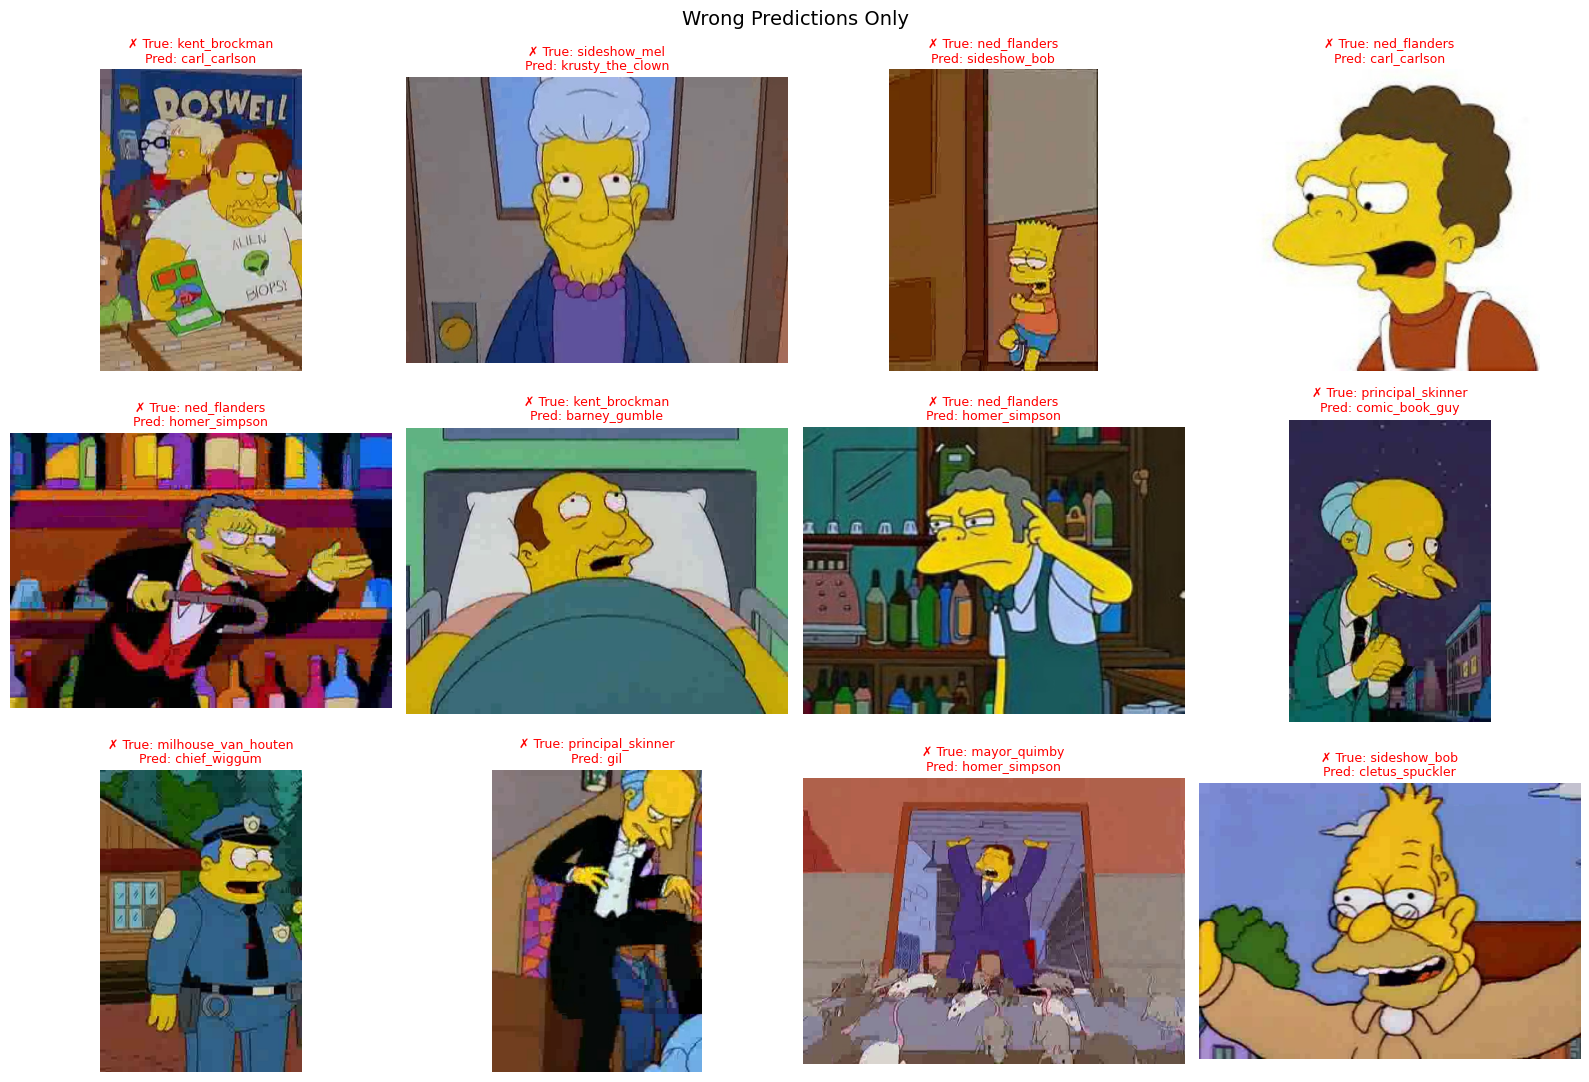


📊 Final summary:
   Correct: 1649
   Wrong:   113
   Total:   1762
   Accuracy: 0.9359


In [5]:
import matplotlib.pyplot as plt
import os, json, random
from PIL import Image

with open("results.json") as f:
    preds = json.load(f)

TEST_DIR = "test_simpsons/test_simpsons"

# Build {filename: true_class} from folder structure
truth = {}
for sub in os.listdir(TEST_DIR):
    sub_path = os.path.join(TEST_DIR, sub)
    if not os.path.isdir(sub_path):
        continue
    for f in os.listdir(sub_path):
        if f.startswith("._") or not f.lower().endswith((".jpg",".jpeg",".png")):
            continue
        truth[f] = sub  # filename -> ground-truth class

def find_image(fname, root):
    for r, _, files in os.walk(root):
        if fname in files:
            return os.path.join(r, fname)
    return None

# ---- 1) Show 16 random predictions with truth ----
sample = random.sample(list(preds.items()), min(16, len(preds)))
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, (fname, pred) in zip(axes.flat, sample):
    path = find_image(fname, TEST_DIR)
    true = truth.get(fname, "?")
    correct = (pred == true)
    color = "green" if correct else "red"
    mark  = "✓" if correct else "✗"
    if path:
        ax.imshow(Image.open(path))
    ax.set_title(f"{mark} True: {true}\nPred: {pred}",
                 fontsize=9, color=color)
    ax.axis("off")
plt.suptitle("Random Sample — Green = Correct, Red = Wrong", fontsize=14)
plt.tight_layout()
plt.show()

# ---- 2) Show 12 WRONG predictions only (more useful for debugging) ----
wrong = [(f, p) for f, p in preds.items() if f in truth and p != truth[f]]
print(f"\nTotal wrong predictions: {len(wrong)} / {len(truth)}")

if wrong:
    sample_wrong = random.sample(wrong, min(12, len(wrong)))
    fig, axes = plt.subplots(3, 4, figsize=(16, 11))
    for ax, (fname, pred) in zip(axes.flat, sample_wrong):
        path = find_image(fname, TEST_DIR)
        true = truth.get(fname, "?")
        if path:
            ax.imshow(Image.open(path))
        ax.set_title(f"✗ True: {true}\nPred: {pred}",
                     fontsize=9, color="red")
        ax.axis("off")
    plt.suptitle("Wrong Predictions Only", fontsize=14)
    plt.tight_layout()
    plt.show()

# ---- 3) Summary printout ----
total = len(truth)
correct = sum(1 for f, p in preds.items() if f in truth and p == truth[f])
print(f"\n📊 Final summary:")
print(f"   Correct: {correct}")
print(f"   Wrong:   {total - correct}")
print(f"   Total:   {total}")
print(f"   Accuracy: {correct/total:.4f}")